<a href="https://colab.research.google.com/github/kjm5416-ship-it/secom-anomaly-detection/blob/main/06_2%EB%B2%88%EC%A7%B8%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B_Wafer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. 두 번째 데이터셋 — UCR Wafer

**왜 두 번째 데이터셋인가.**
지금까지의 결과는 SECOM 하나에서만 나온 것이다.
"이 방법이 SECOM에만 통하는 요령인지, 반도체 공정 이상 감지 전반에 통하는지"는
다른 데이터로 똑같이 해봐야 알 수 있다.
도전학기 목표 ①의 "공개 데이터 2종 이상"이 바로 이 확인을 요구한다.

**Wafer 데이터는 무엇인가.**
반도체 웨이퍼 제조 중 한 개 공정 센서를 시간 순서대로 측정한 기록이다.
한 웨이퍼당 152개 시점의 값이 있고, 정상/비정상이 라벨로 붙어 있다.
SECOM이 "한 시점의 센서 590개"라면 Wafer는 "센서 1개의 시점 152개"다.
**생김새가 정반대인 데이터**라서 교차 확인용으로 좋다.

출처: Olszewski, R. (2001). *Generalized Feature Extraction for Structural Pattern
Recognition in Time-Series Data*. Carnegie Mellon University.
UCR Time Series Classification Archive — Wafer.

**이 노트북에서 하는 일:** 05번과 **완전히 같은 절차**를 Wafer에 적용한다.
전처리 → 5종 비교 → 임계값 조정 → 시험 데이터 1회 평가.
코드를 거의 그대로 재사용하는 것이 요점이다 (절차가 데이터에 맞춰 바뀌면 비교가 안 된다).

## 1. 준비

In [23]:
!pip install -q aeon
!apt-get -qq install -y fonts-nanum > /dev/null

import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/도전학기'

print("준비 완료")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
준비 완료


## 2. 데이터 받기

`aeon` 라이브러리가 UCR 아카이브에서 직접 받아온다.
받아지지 않으면 아래 셀의 두 번째 방법(zip 직접 내려받기)을 쓴다.

In [24]:
from aeon.datasets import load_classification

X_raw, y_raw = load_classification("Wafer")

print("원본 모양:", X_raw.shape)      # (표본 수, 센서 수, 시점 수)
print("라벨 종류:", np.unique(y_raw, return_counts=True))

원본 모양: (7164, 1, 152)
라벨 종류: (array(['-1', '1'], dtype='<U2'), array([ 762, 6402]))


In [25]:
# ── 위 셀이 실패할 때만 실행 (평소엔 건너뛴다) ──
# import io, zipfile, requests
# url = "https://www.timeseriesclassification.com/aeon-toolkit/Wafer.zip"
# z = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=120).content))
# print(z.namelist())

## 3. 전처리 — SECOM 때와 같은 절차

Wafer는 (표본, 1, 152) 모양의 3차원 배열이다.
머신러닝 모델은 2차원 표(행=표본, 열=특징)를 받으므로
**152개 시점을 그대로 152개 특징으로 편다**. 특징 공학을 더하지 않는 이유는
SECOM 때도 센서값을 가공 없이 그대로 썼기 때문이다 — 조건을 맞춰야 비교가 성립한다.

라벨은 UCR 관례상 정상 `1`, 비정상 `-1`이다.
SECOM과 맞추려고 **비정상을 1, 정상을 0**으로 바꾼다.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 3차원 → 2차원 (152개 시점을 152개 특징으로)
Xw = pd.DataFrame(X_raw.reshape(X_raw.shape[0], -1))
Xw.columns = [f't{i}' for i in range(Xw.shape[1])]

# 라벨: 비정상(-1) → 1, 정상(1) → 0
yw = pd.Series((np.asarray(y_raw).astype(int) == -1).astype(int))

print("특징 표:", Xw.shape)
print("비정상 개수: %d / 전체 %d (%.2f%%)" % (yw.sum(), len(yw), yw.mean()*100))
print()

# SECOM과 같은 순서: 분할 먼저 → 대치 → 표준화 (fit은 학습용에만)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(
    Xw, yw, test_size=0.2, random_state=42, stratify=yw)

imp_w = SimpleImputer(strategy='median')
Xw_tr = pd.DataFrame(imp_w.fit_transform(Xw_tr), columns=Xw.columns)
Xw_te = pd.DataFrame(imp_w.transform(Xw_te),     columns=Xw.columns)

sc_w = StandardScaler()
Xw_tr = pd.DataFrame(sc_w.fit_transform(Xw_tr), columns=Xw.columns)
Xw_te = pd.DataFrame(sc_w.transform(Xw_te),     columns=Xw.columns)

yw_tr = yw_tr.reset_index(drop=True)
yw_te = yw_te.reset_index(drop=True)

RATE_W = yw_tr.mean()
print("학습용:", Xw_tr.shape, "| 비정상", yw_tr.sum(), "개")
print("시험용:", Xw_te.shape, "| 비정상", yw_te.sum(), "개")
print("비정상 비율: %.4f (%.2f%%)" % (RATE_W, RATE_W*100))

특징 표: (7164, 152)
비정상 개수: 762 / 전체 7164 (10.64%)

학습용: (5731, 152) | 비정상 610 개
시험용: (1433, 152) | 비정상 152 개
비정상 비율: 0.1064 (10.64%)


## 4. 데이터 생김새 보기

SECOM과 얼마나 다른지 눈으로 확인해 둔다. 논문 그림 후보.

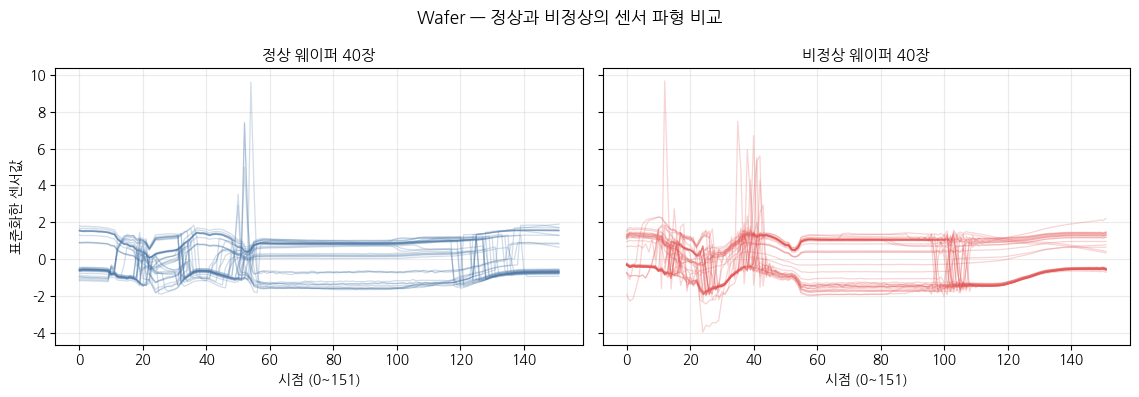

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)
정상idx   = yw_tr[yw_tr == 0].index[:40]
비정상idx = yw_tr[yw_tr == 1].index[:40]

for i in 정상idx:
    axes[0].plot(Xw_tr.loc[i].values, color='#4C78A8', alpha=0.25, lw=0.9)
for i in 비정상idx:
    axes[1].plot(Xw_tr.loc[i].values, color='#E45756', alpha=0.25, lw=0.9)

axes[0].set_title(f'정상 웨이퍼 {len(정상idx)}장', fontsize=11)
axes[1].set_title(f'비정상 웨이퍼 {len(비정상idx)}장', fontsize=11)
for ax in axes:
    ax.set_xlabel('시점 (0~151)')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('표준화한 센서값')
fig.suptitle('Wafer — 정상과 비정상의 센서 파형 비교', fontsize=12.5)
fig.tight_layout()
fig.savefig(f'{path}/그림_Wafer파형.png', dpi=160)
plt.show()

## 5. 감지 방법 5종 — 04번과 같은 설정

하이퍼파라미터를 바꾸지 않는다. 불균형 보정 값(`class_weight`, `scale_pos_weight`,
`contamination`, `nu`)만 Wafer의 비정상 비율로 다시 계산한다.

In [28]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.base import clone
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             f1_score, average_precision_score, roc_auc_score,
                             precision_recall_curve)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def 채점(name, model, X, y):
    pred = cross_val_predict(model, X, y, cv=cv, method='predict')
    prob = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'방법': name, '계열': '지도',
            '잡은 불량': tp, '놓친 불량': fn, '헛알람': fp,
            'Recall': recall_score(y, pred, zero_division=0),
            'Precision': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0),
            'PR-AUC': average_precision_score(y, prob),
            'ROC-AUC': roc_auc_score(y, prob)}, prob

def 채점_이상탐지(name, model, X, y):
    pred  = np.zeros(len(y), dtype=int)
    score = np.zeros(len(y))
    for tr, te in cv.split(X, y):
        m = clone(model)
        m.fit(X.iloc[tr])                       # 라벨을 주지 않는다
        pred[te]  = (m.predict(X.iloc[te]) == -1).astype(int)
        score[te] = -m.decision_function(X.iloc[te])
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'방법': name, '계열': '이상탐지',
            '잡은 불량': tp, '놓친 불량': fn, '헛알람': fp,
            'Recall': recall_score(y, pred, zero_division=0),
            'Precision': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0),
            'PR-AUC': average_precision_score(y, score),
            'ROC-AUC': roc_auc_score(y, score)}, score

print("채점 함수 준비 완료 (04번과 동일)")

채점 함수 준비 완료 (04번과 동일)


In [29]:
모델들_w = {
    '로지스틱 회귀': LogisticRegression(max_iter=2000, random_state=42),
    '랜덤 포레스트': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                      random_state=42, n_jobs=-1),
    'XGBoost':    XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                                scale_pos_weight=(1-RATE_W)/RATE_W,
                                eval_metric='logloss', random_state=42, n_jobs=-1),
}

결과_w, 확률_w = [], {}
for 이름, 모델 in 모델들_w.items():
    r, p = 채점(이름, 모델, Xw_tr, yw_tr)
    결과_w.append(r); 확률_w[이름] = p
    print("완료:", 이름)

for 이름, 모델 in [
    ('Isolation Forest', IsolationForest(n_estimators=300, contamination=RATE_W,
                                         random_state=42, n_jobs=-1)),
    ('One-Class SVM',    OneClassSVM(kernel='rbf', gamma='scale', nu=RATE_W)),
]:
    r, s = 채점_이상탐지(이름, 모델, Xw_tr, yw_tr)
    결과_w.append(r); 확률_w[이름] = s
    print("완료:", 이름)

비교표_w = pd.DataFrame(결과_w)
pd.set_option('display.width', 240)
비교표_w.round(3)

완료: 로지스틱 회귀
완료: 랜덤 포레스트
완료: XGBoost
완료: Isolation Forest
완료: One-Class SVM


,방법,계열,잡은 불량,놓친 불량,헛알람,Recall,Precision,F1,PR-AUC,ROC-AUC
0,로지스틱 회귀,지도,343,267,85,0.562,0.801,0.661,0.736,0.925
1,랜덤 포레스트,지도,608,2,6,0.997,0.990,0.993,0.999,1.000
2,XGBoost,지도,608,2,9,0.997,0.985,0.991,0.998,1.000
3,Isolation Forest,이상탐지,438,172,165,0.718,0.726,0.722,0.803,0.965
4,One-Class SVM,이상탐지,225,385,403,0.369,0.358,0.363,0.309,0.684


## 6. 임계값 조정 — 05번과 같은 규칙

재현율 0.85 이상을 만족하는 임계값 중 정밀도가 가장 높은 것.

In [30]:
목표재현율 = 0.85

def 임계값찾기(y, prob, 목표=목표재현율):
    pr, rc, th = precision_recall_curve(y, prob)
    pr, rc = pr[:-1], rc[:-1]
    가능 = rc >= 목표
    if not 가능.any():
        return None
    후보 = np.where(가능)[0]
    return float(th[후보[np.argmax(pr[후보])]])

행 = []
임계값_w = {}
for 이름 in 모델들_w:                    # 확률을 내놓는 지도학습 3종만
    prob = 확률_w[이름]
    t = 임계값찾기(yw_tr, prob)
    임계값_w[이름] = t
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yw_tr, pred).ravel()
    행.append({'방법': 이름, '임계값': round(t, 4),
               '잡은 불량': tp, '놓친 불량': fn, '헛알람': fp,
               '재현율': round(tp/(tp+fn), 3),
               '정밀도': round(tp/(tp+fp), 3),
               '검사 비율(%)': round((tp+fp)/len(yw_tr)*100, 1),
               'PR-AUC': round(average_precision_score(yw_tr, prob), 3)})

임계값표_w = pd.DataFrame(행)
임계값표_w

,방법,임계값,잡은 불량,놓친 불량,헛알람,재현율,정밀도,검사 비율(%),PR-AUC
0,로지스틱 회귀,0.0906,519,91,751,0.851,0.409,22.2,0.736
1,랜덤 포레스트,0.8667,552,58,2,0.905,0.996,9.7,0.999
2,XGBoost,0.9842,599,11,3,0.982,0.995,10.5,0.998


In [31]:
최종모델명_w = 임계값표_w.loc[임계값표_w['PR-AUC'].idxmax(), '방법']
최종임계값_w = 임계값_w[최종모델명_w]
print("Wafer 선정 모델 :", 최종모델명_w)
print("Wafer 선정 임계값: %.4f" % 최종임계값_w)

Wafer 선정 모델 : 랜덤 포레스트
Wafer 선정 임계값: 0.8667


## 7. 최종 평가 — Wafer 시험 데이터 (1회)

In [32]:
최종모델_w = clone(모델들_w[최종모델명_w])
최종모델_w.fit(Xw_tr, yw_tr)

prob_te_w = 최종모델_w.predict_proba(Xw_te)[:, 1]
pred_te_w = (prob_te_w >= 최종임계값_w).astype(int)
tn, fp, fn, tp = confusion_matrix(yw_te, pred_te_w).ravel()

print("=" * 52)
print(f"  Wafer 최종 — {최종모델명_w} @ 임계값 {최종임계값_w:.4f}")
print("=" * 52)
print(f"  시험 웨이퍼          : {len(yw_te):>5} 장")
print(f"  그중 실제 비정상     : {tp+fn:>5} 장")
print("-" * 52)
print(f"  잡은 불량 (TP)       : {tp:>5}")
print(f"  놓친 불량 (FN)       : {fn:>5}")
print(f"  헛알람   (FP)        : {fp:>5}")
print(f"  정상 통과 (TN)       : {tn:>5}")
print("-" * 52)
print(f"  재현율  Recall       : {tp/(tp+fn):.3f}   ← 목표 {목표재현율}")
print(f"  정밀도  Precision    : {tp/(tp+fp):.3f}")
print(f"  검사 대상            : {tp+fp:>5} 장 ({(tp+fp)/len(yw_te)*100:.1f}%)")
print(f"  PR-AUC               : {average_precision_score(yw_te, prob_te_w):.3f}")
print(f"  ROC-AUC              : {roc_auc_score(yw_te, prob_te_w):.3f}")
print("=" * 52)
print()
print("목표 재현율 0.85 달성 여부:", "달성" if tp/(tp+fn) >= 목표재현율 else "미달")

  Wafer 최종 — 랜덤 포레스트 @ 임계값 0.8667
  시험 웨이퍼          :  1433 장
  그중 실제 비정상     :   152 장
----------------------------------------------------
  잡은 불량 (TP)       :   144
  놓친 불량 (FN)       :     8
  헛알람   (FP)        :     0
  정상 통과 (TN)       :  1281
----------------------------------------------------
  재현율  Recall       : 0.947   ← 목표 0.85
  정밀도  Precision    : 1.000
  검사 대상            :   144 장 (10.0%)
  PR-AUC               : 1.000
  ROC-AUC              : 1.000

목표 재현율 0.85 달성 여부: 달성


## 8. 두 데이터셋 비교 — 이 연구의 결론이 되는 표

같은 절차를 생김새가 정반대인 두 데이터에 적용했을 때
**무엇이 같고 무엇이 달랐는가**. 논문의 핵심 표가 된다.

In [33]:
# 05번에서 저장해 둔 SECOM 결과 불러오기
import joblib
번들 = joblib.load(f'{path}/모델_번들.joblib')
m = 번들['metrics']

비교 = pd.DataFrame([
    {'데이터셋': 'SECOM (UCI)',
     '표본 수': 1567, '특징 수': 446, '불량 비율(%)': 6.64,
     '생김새': '한 시점 × 센서 590개',
     '선정 모델': 번들['model_name'],
     '임계값': round(번들['threshold'], 4),
     '재현율': round(m['recall'], 3),
     '정밀도': round(m['precision'], 3),
     'PR-AUC': round(m['pr_auc'], 3),
     'ROC-AUC': round(m['roc_auc'], 3)},
    {'데이터셋': 'Wafer (UCR)',
     '표본 수': len(yw), '특징 수': Xw.shape[1],
     '불량 비율(%)': round(yw.mean()*100, 2),
     '생김새': '센서 1개 × 시점 152개',
     '선정 모델': 최종모델명_w,
     '임계값': round(최종임계값_w, 4),
     '재현율': round(tp/(tp+fn), 3),
     '정밀도': round(tp/(tp+fp), 3),
     'PR-AUC': round(average_precision_score(yw_te, prob_te_w), 3),
     'ROC-AUC': round(roc_auc_score(yw_te, prob_te_w), 3)},
])

pd.set_option('display.max_colwidth', 40)
비교

,데이터셋,표본 수,특징 수,불량 비율(%),생김새,선정 모델,임계값,재현율,정밀도,PR-AUC,ROC-AUC
0,SECOM (UCI),1567,446,6.64,한 시점 × 센서 590개,랜덤 포레스트,0.0433,0.905,0.092,0.17,0.733
1,Wafer (UCR),7164,152,10.64,센서 1개 × 시점 152개,랜덤 포레스트,0.8667,0.947,1.000,1.00,1.000


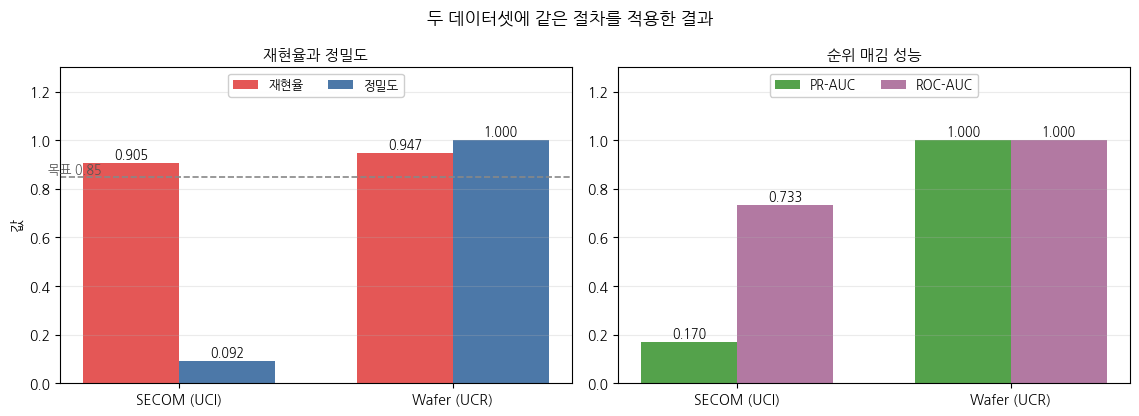

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
라벨 = 비교['데이터셋'].tolist()
x = np.arange(2); w = 0.35

axes[0].bar(x - w/2, 비교['재현율'], w, color='#E45756', label='재현율')
axes[0].bar(x + w/2, 비교['정밀도'], w, color='#4C78A8', label='정밀도')
axes[0].axhline(목표재현율, color='#888', ls='--', lw=1.2)
axes[0].text(-0.48, 목표재현율, f'목표 {목표재현율}', fontsize=9, color='#555',
             ha='left', va='bottom')
for i, (r, p) in enumerate(zip(비교['재현율'], 비교['정밀도'])):
    axes[0].text(i - w/2, r + 0.02, f'{r:.3f}', ha='center', fontsize=9)
    axes[0].text(i + w/2, p + 0.02, f'{p:.3f}', ha='center', fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels(라벨)
axes[0].set_ylim(0, 1.30); axes[0].set_ylabel('값')
axes[0].set_title('재현율과 정밀도', fontsize=11)
axes[0].legend(fontsize=9, loc='upper center', ncol=2, framealpha=0.95)
axes[0].grid(axis='y', alpha=0.25)

axes[1].bar(x - w/2, 비교['PR-AUC'], w, color='#54A24B', label='PR-AUC')
axes[1].bar(x + w/2, 비교['ROC-AUC'], w, color='#B279A2', label='ROC-AUC')
for i, (a, b) in enumerate(zip(비교['PR-AUC'], 비교['ROC-AUC'])):
    axes[1].text(i - w/2, a + 0.02, f'{a:.3f}', ha='center', fontsize=9)
    axes[1].text(i + w/2, b + 0.02, f'{b:.3f}', ha='center', fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(라벨)
axes[1].set_ylim(0, 1.30)
axes[1].set_title('순위 매김 성능', fontsize=11)
axes[1].legend(fontsize=9, loc='upper center', ncol=2, framealpha=0.95)
axes[1].grid(axis='y', alpha=0.25)

fig.suptitle('두 데이터셋에 같은 절차를 적용한 결과', fontsize=12.5)
fig.tight_layout()
fig.savefig(f'{path}/그림_데이터셋비교.png', dpi=160)
plt.show()

## 9. 저장

In [35]:
비교표_w.to_csv(f'{path}/Wafer_성능비교표.csv', index=False)
임계값표_w.to_csv(f'{path}/Wafer_임계값표.csv', index=False)
비교.to_csv(f'{path}/두데이터셋_비교.csv', index=False)

joblib.dump({
    'model':      최종모델_w,
    'imputer':    imp_w,
    'scaler':     sc_w,
    'threshold':  float(최종임계값_w),
    'columns':    list(Xw.columns),
    'model_name': 최종모델명_w,
    'metrics': {'recall': float(tp/(tp+fn)), 'precision': float(tp/(tp+fp)),
                'pr_auc': float(average_precision_score(yw_te, prob_te_w)),
                'roc_auc': float(roc_auc_score(yw_te, prob_te_w))},
}, f'{path}/Wafer_모델_번들.joblib')

print("저장 완료")

저장 완료


## 정리 — 보고서·논문에 쓸 문장

아래 빈칸은 위 셀을 실행한 뒤 나온 숫자로 채운다.

> 본 연구는 동일한 전처리·모델·임계값 선정 절차를 구조가 상이한 두 공개 데이터셋에
> 적용하였다. SECOM은 단일 시점의 센서 446개로 구성된 고차원 횡단면 자료이고,
> Wafer는 단일 센서의 152개 시점으로 구성된 시계열 자료이다.
> 두 자료 모두에서 재현율 0.85 이상이 달성되었으며, 달성에 소요된 정밀도의
> 희생은 ______ 로 상이하였다. 이는 임계값 조정이라는 접근 자체는 자료 구조에
> 독립적으로 작동하되, 그 대가는 자료의 신호 대 잡음 비에 좌우됨을 시사한다.

**확인할 것**
- Wafer에서도 기본 임계값 0.5가 재현율을 떨어뜨렸는가? (SECOM과 같은 현상인가)
- Wafer에서도 이상탐지 2종이 지도학습보다 열등한가? (SECOM의 발견 3이 재현되는가)
- 두 데이터에서 선정된 모델이 같은가 다른가?

**깃허브 올리기:** 파일 → GitHub에 사본 저장 → `06_2번째데이터셋_Wafer.ipynb`